# SARIMA — Previsão do Preço Diário do Trigo no RS (Baseline Univariado)

**TCC — Sistemas de Informação | PUCRS**
Bruno Origem Noronha

Este notebook implementa o **SARIMA** em **granularidade diária** para o trigo, seguindo o mesmo padrão metodológico do
notebook do arroz (`sarima_arroz.ipynb`). É um modelo **univariado**: prevê o preço do trigo usando **somente o histórico
do próprio preço**, sem nenhuma variável externa.

- **Variável alvo (y):** preço diário do trigo no Rio Grande do Sul, em reais por tonelada (`preco_brl`, Indicador CEPEA/ESALQ - RS)
- **Variáveis exógenas:** nenhuma
- **Fonte:** `data/processed/dataset_final_trigo.csv` (dataset integrado do trigo, do qual usamos apenas a coluna de preço)

Diferentemente do arroz, em que uma única especificação foi ajustada, aqui **comparamos três estruturas candidatas**,
sugeridas pela análise de autocorrelação da EDA do trigo (`analise_exploratoria_trigo.ipynb`):

| Candidato | Parte não sazonal | Parte sazonal |
|---|---|---|
| SARIMA(1,1,1)(1,0,1)[7] | AR(1) + MA(1) | AR + MA semanais |
| SARIMA(0,1,1)(1,0,1)[7] | apenas MA(1) | AR + MA semanais |
| SARIMA(1,1,0)(1,0,1)[7] | apenas AR(1) | AR + MA semanais |

Roteiro:
1. Carregamento, preparação diária e divisão cronológica (treino até 31/01/2026 · teste nos 30 dias seguintes, de 01/02 a 02/03/2026)
2. Análise de estacionariedade (teste ADF)
3. Ajuste dos três modelos SARIMA candidatos
4. Previsão no período de teste e métricas (AIC, BIC, RMSE, MAE, MAPE)
5. Visualização gráfica e exportação

In [1]:
# Bibliotecas
import os
import warnings
warnings.filterwarnings("ignore")   # esconde avisos internos das bibliotecas, para a saída ficar limpa

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from statsmodels.tsa.stattools import adfuller           # teste de estacionariedade
from statsmodels.tsa.statespace.sarimax import SARIMAX   # usado aqui sem exógenas, ou seja, como SARIMA puro

# Pasta onde salvamos o gráfico e as métricas
PASTA_SAIDA = "outputs"
os.makedirs(PASTA_SAIDA, exist_ok=True)

## 1. Carregamento e preparação diária

### 1.1 Leitura e estrutura do índice temporal

- Lemos o arquivo `dataset_final_trigo.csv` e usamos a coluna `data` como **índice de tempo**.
- Mantemos **apenas** a coluna `preco_brl`: o modelo é univariado.
- Fixamos a **frequência diária** com `asfreq("D")`. Isso garante um registro para cada dia do calendário e informa ao
  `statsmodels` que a série é diária, o que é necessário para datar corretamente as previsões.
- **Dias sem cotação** (fins de semana, feriados ou falhas de coleta) recebem o **último preço conhecido** (`ffill`).
  O dataset final já vem com o calendário contínuo, então o `ffill` funciona aqui como uma **garantia**: a contagem abaixo deve ser zero.
- O dataset final começa em **01/02/2008**, pois o primeiro mês da série de preços é consumido pelas defasagens de 30 dias criadas na engenharia de atributos.

In [2]:
# Lê o CSV, usando a coluna "data" como índice de tempo
trigo = pd.read_csv("../data/processed/dataset_final_trigo.csv", parse_dates=["data"], index_col="data")

# Série univariada com frequência diária contínua
y = trigo["preco_brl"].asfreq("D")

print(f"Dias sem cotação antes do tratamento: {y.isna().sum()}")
y = y.ffill()   # dias sem cotação recebem o último preço conhecido

print(f"Período total: {y.index[0]:%d/%m/%Y} a {y.index[-1]:%d/%m/%Y} ({len(y)} dias)")
y.head()

Dias sem cotação antes do tratamento: 0
Período total: 01/02/2008 a 20/04/2026 (6654 dias)


data
2008-02-01    490.41
2008-02-02    490.41
2008-02-03    490.41
2008-02-04    490.41
2008-02-05    490.41
Freq: D, Name: preco_brl, dtype: float64

### 1.2 Divisão cronológica: treino vs. teste

Em séries temporais a divisão **nunca é aleatória**: o modelo só pode aprender com o passado e ser avaliado no futuro.
A divisão é **idêntica à do arroz**:

| Conjunto | Período | Justificativa |
|---|---|---|
| **Treino** | início da série até **31/01/2026** | o modelo absorve todo o histórico, incluindo choques como a **pandemia de 2020** e o pico de preços durante a **guerra Rússia–Ucrânia em 2022** |
| **Teste** | **01/02/2026 a 02/03/2026** (30 dias) | horizonte de **curto prazo**, coerente com o uso prático de uma previsão diária |

A constante `HORIZONTE` define o tamanho do teste e pode ser ajustada entre 15 e 30 dias (mantendo o mesmo valor nos demais modelos).

In [3]:
FIM_TREINO = "2026-01-31"
HORIZONTE  = 30   # dias de teste a partir de 01/02/2026 (entre 15 e 30)

y_treino = y.loc[:FIM_TREINO]
y_teste  = y.loc["2026-02-01":].iloc[:HORIZONTE]

print(f"Treino: {len(y_treino)} dias ({y_treino.index[0]:%d/%m/%Y} a {y_treino.index[-1]:%d/%m/%Y})")
print(f"Teste : {len(y_teste)} dias ({y_teste.index[0]:%d/%m/%Y} a {y_teste.index[-1]:%d/%m/%Y})")

Treino: 6575 dias (01/02/2008 a 31/01/2026)
Teste : 30 dias (01/02/2026 a 02/03/2026)


### 1.3 Visão geral da série de treino

Os destaques marcam os dois choques que o treino precisa conter: a **pandemia (2020)** e o período de **guerra Rússia–Ucrânia (2022)**,
quando o trigo gaúcho atingiu sua máxima histórica.

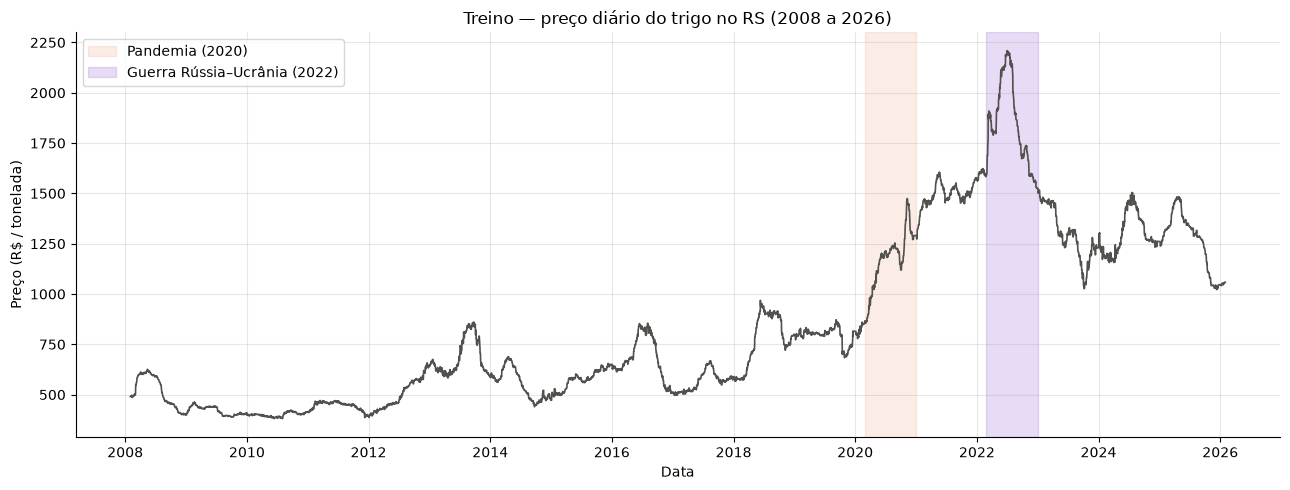

In [4]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(y_treino, color="#52514e", lw=1.2)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-12-31"), color="#eb6834", alpha=0.12, label="Pandemia (2020)")
ax.axvspan(pd.Timestamp("2022-02-24"), pd.Timestamp("2022-12-31"), color="#7a3cc8", alpha=0.18, label="Guerra Rússia–Ucrânia (2022)")

ax.set_title("Treino — preço diário do trigo no RS (2008 a 2026)")
ax.set_xlabel("Data")
ax.set_ylabel("Preço (R$ / tonelada)")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 2. Análise de estacionariedade (teste ADF)

Os modelos ARIMA/SARIMA exigem uma série **estacionária**: média e variância estáveis ao longo do tempo.
O teste **ADF (Augmented Dickey-Fuller)** verifica isso:

- **Hipótese nula (H₀):** a série tem raiz unitária, ou seja, **não é estacionária**.
- **Regra de decisão:** p-valor **< 0,05** → rejeitamos H₀ → a série é estacionária.

Testamos o preço no nível original e na **primeira diferença** (variação de um dia para o outro).
Se o preço só ficar estacionário após diferenciar, usamos **d = 1**.

In [5]:
def teste_adf(s, nome):
    estatistica, p_valor = adfuller(s)[:2]   # 1º item: estatística; 2º item: p-valor
    conclusao = "estacionária" if p_valor < 0.05 else "NÃO estacionária"
    print(f"{nome:<24} ADF = {estatistica:8.3f}   p-valor = {p_valor:.4f}  ->  {conclusao}")

teste_adf(y_treino,                 "Trigo — original")
teste_adf(y_treino.diff().dropna(), "Trigo — 1ª diferença")

Trigo — original         ADF =   -1.421   p-valor = 0.5721  ->  NÃO estacionária
Trigo — 1ª diferença     ADF =  -13.437   p-valor = 0.0000  ->  estacionária


**Leitura:**

- O **preço original não é estacionário** (p-valor acima de 0,05): ele tem tendência de longo prazo e mudanças de patamar.
- A **primeira diferença é estacionária**, portanto adotamos **d = 1** nos três candidatos: os modelos trabalham com as **variações diárias** do preço.
  O resultado confirma os testes ADF e KPSS da análise exploratória do trigo.

### 2.1 Por que sazonalidade semanal (s = 7)?

Com dados diários, o período sazonal `s` precisa refletir um ciclo real e computacionalmente viável:

- **s = 365 (anual)** tornaria o modelo inviável: o espaço de estados teria centenas de dimensões e o ajuste levaria horas, com alto risco de não convergir.
  O ciclo anual da safra de inverno identificado na EDA fica a cargo das variáveis sazonais (seno/cosseno) nos modelos multivariados.
- **s = 7 (semanal)** captura um padrão concreto da série: **não há pregão aos sábados e domingos**, então o preço é repetido nesses dias
  e a variação diária é sempre zero. Na EDA do trigo, o **lag 7** foi justamente o pico dominante da ACF e da PACF. A tabela abaixo comprova o padrão.

In [6]:
variacao = y_treino.diff().dropna()
dias = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado", "Domingo"]

pd.DataFrame({
    "% de dias sem variação": (variacao == 0).groupby(variacao.index.dayofweek).mean().mul(100).round(1).values,
    "Variação absoluta média (R$)": variacao.abs().groupby(variacao.index.dayofweek).mean().round(3).values,
}, index=dias)

,% de dias sem variação,Variação absoluta média (R$)
Segunda,8.3,5.447
Terça,8.1,5.702
Quarta,7.6,5.912
Quinta,9.8,5.027
Sexta,10.5,5.166
Sábado,100.0,0.000
Domingo,100.0,0.000


Sábados e domingos têm **100% dos dias sem variação**: é um ciclo semanal determinístico que o componente sazonal com `s = 7` aprende a reproduzir.

## 3. Ajuste dos modelos SARIMA candidatos

O modelo é **SARIMA(p, d, q)(P, D, Q, s)**. Na biblioteca `statsmodels` ele é ajustado com a classe `SARIMAX`
**sem o argumento `exog`**: sem variáveis exógenas, o SARIMAX se reduz exatamente a um SARIMA univariado.

Os três candidatos compartilham **d = 1**, a parte sazonal **(P, D, Q, s) = (1, 0, 1, 7)** e diferem apenas na parte não sazonal:

| Parâmetro | (1,1,1) | (0,1,1) | (1,1,0) | Significado |
|---|---|---|---|---|
| **p** | 1 | 0 | 1 | usa a variação do **dia anterior** (parte autorregressiva) |
| **d** | 1 | 1 | 1 | **1 diferenciação** para tornar a série estacionária (resultado do ADF) |
| **q** | 1 | 1 | 0 | corrige pelo **erro de previsão do dia anterior** (média móvel) |
| **P** | 1 | 1 | 1 | usa a variação do **mesmo dia da semana anterior** (autorregressivo sazonal) |
| **D** | 0 | 0 | 0 | sem diferenciação sazonal: a variação diária já é estacionária |
| **Q** | 1 | 1 | 1 | corrige pelo erro do **mesmo dia da semana anterior** (média móvel sazonal) |
| **s** | 7 | 7 | 7 | ciclo sazonal **semanal** (dados diários, sem pregão no fim de semana) |

Na forma mais completa, SARIMA(1,1,1)(1,0,1)[7], com $B$ sendo o operador de defasagem ($B\,y_t = y_{t-1}$):

$$(1 - \phi_1 B)(1 - \Phi_1 B^{7})\,(1 - B)\,y_t = (1 + \theta_1 B)(1 + \Theta_1 B^{7})\,\varepsilon_t$$

- $(1 - B)\,y_t = y_t - y_{t-1}$ é a variação diária (d = 1);
- $\phi_1$ e $\theta_1$ são os termos AR e MA do dia anterior (no candidato (0,1,1) fixa-se $\phi_1 = 0$; no (1,1,0), $\theta_1 = 0$);
- $\Phi_1$ e $\Theta_1$ são os termos AR e MA sazonais, que olham 7 dias para trás;
- $\varepsilon_t$ é o erro aleatório (ruído branco).

**Por que testar variantes mais simples?** Na EDA do trigo, a autocorrelação da variação diária no lag 1 foi praticamente nula (≈ −0,01).
Isso sugere que talvez **um único termo** não sazonal (ou nenhum) baste. Os modelos (0,1,1) e (1,1,0) têm um parâmetro a menos e permitem
verificar se a estrutura completa do arroz é realmente necessária para o trigo.

Todos são ajustados **apenas com o treino**, com `maxiter=200` para garantir a convergência do otimizador.

In [7]:
ORDEM_SAZONAL = (1, 0, 1, 7)   # (P, D, Q, s) — comum aos três candidatos
CANDIDATOS = [(1, 1, 1), (0, 1, 1), (1, 1, 0)]   # (p, d, q)

def nome_modelo(ordem):
    p, d, q = ordem
    P, D, Q, s = ORDEM_SAZONAL
    return f"SARIMA({p},{d},{q})({P},{D},{Q})[{s}]"

resultados = {}
for ordem in CANDIDATOS:
    modelo = SARIMAX(endog=y_treino, order=ordem, seasonal_order=ORDEM_SAZONAL)   # sem exog -> SARIMA univariado
    resultados[ordem] = modelo.fit(disp=False, maxiter=200)   # disp=False esconde as mensagens da otimização
    r = resultados[ordem]
    print(f"{nome_modelo(ordem):<26} convergiu: {r.mle_retvals['converged']}   AIC = {r.aic:,.1f}   BIC = {r.bic:,.1f}")

SARIMA(1,1,1)(1,0,1)[7]    convergiu: True   AIC = 45,830.5   BIC = 45,864.4


SARIMA(0,1,1)(1,0,1)[7]    convergiu: True   AIC = 45,832.5   BIC = 45,859.6


SARIMA(1,1,0)(1,0,1)[7]    convergiu: True   AIC = 45,832.2   BIC = 45,859.3


### 3.1 Coeficientes estimados

A tabela reúne os coeficientes de cada candidato e seus p-valores. Um termo com p-valor abaixo de 0,05 contribui de forma significativa para o modelo.

In [8]:
coeficientes = pd.DataFrame({
    nome_modelo(o): r.params.round(4).astype(str) + "  (p=" + r.pvalues.round(4).astype(str) + ")"
    for o, r in resultados.items()
}).fillna("—")
coeficientes

,"SARIMA(1,1,1)(1,0,1)[7]","SARIMA(0,1,1)(1,0,1)[7]","SARIMA(1,1,0)(1,0,1)[7]"
ar.L1,-0.8516 (p=0.0),—,-0.0311 (p=0.0)
ar.S.L7,0.6192 (p=0.0),0.6412 (p=0.0),0.6414 (p=0.0)
ma.L1,0.8309 (p=0.0),-0.0294 (p=0.0),—
ma.S.L7,-0.5101 (p=0.0),-0.5367 (p=0.0),-0.5369 (p=0.0)
sigma2,62.3008 (p=0.0),62.3434 (p=0.0),62.3405 (p=0.0)


### 3.2 Resumo completo do modelo de referência

Exibimos o resumo completo da especificação de referência, SARIMA(1,1,1)(1,0,1)[7], a mesma utilizada no arroz.

**Como ler o resumo:**

- **coef / P>|z|:** cada termo (`ar.L1`, `ma.L1`, `ar.S.L7`, `ma.S.L7`) com p-valor abaixo de 0,05 contribui de forma significativa para o modelo.
- **sigma2:** variância do erro, ou seja, o tamanho típico da "surpresa" diária que o modelo não consegue explicar.
- **AIC / BIC:** critérios de informação; quanto menor, melhor o equilíbrio entre ajuste e número de parâmetros. O BIC penaliza mais fortemente parâmetros extras.
- **Ljung-Box (Prob(Q)):** acima de 0,05 indica que os resíduos não têm autocorrelação, ou seja, o modelo capturou a dependência temporal.

In [9]:
print(resultados[(1, 1, 1)].summary())

                                     SARIMAX Results                                     
Dep. Variable:                         preco_brl   No. Observations:                 6575
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 7)   Log Likelihood              -22910.247
Date:                           Mon, 09 Nov 2026   AIC                          45830.493
Time:                                   12:25:23   BIC                          45864.448
Sample:                               02-01-2008   HQIC                         45842.230
                                    - 01-31-2026                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8516      0.063    -13.603      0.000      -0.974      -0.729
ma.L1          0.8309      0.065     12.770

### 3.3 Diagnóstico dos resíduos: Ljung-Box em várias defasagens

O resumo acima mostra o Ljung-Box apenas na **defasagem 1**. Como a EDA do trigo revelou autocorrelações fracas espalhadas pelas
primeiras semanas, testamos também as defasagens 7, 14 e 28 nos três candidatos. Lembrando: **p-valor acima de 0,05** indica que não há
autocorrelação residual significativa até aquela defasagem.

In [10]:
from statsmodels.stats.diagnostic import acorr_ljungbox

LAGS_LB = [1, 7, 14, 28]
ljung_box = pd.DataFrame({
    nome_modelo(o): acorr_ljungbox(r.resid.iloc[1:], lags=LAGS_LB)["lb_pvalue"].values   # descarta o 1º resíduo (efeito da diferenciação)
    for o, r in resultados.items()
}, index=[f"p-valor até lag {k}" for k in LAGS_LB]).round(4)
ljung_box

,"SARIMA(1,1,1)(1,0,1)[7]","SARIMA(0,1,1)(1,0,1)[7]","SARIMA(1,1,0)(1,0,1)[7]"
p-valor até lag 1,0.4378,0.9414,0.9529
p-valor até lag 7,0.0000,0.0000,0.0000
p-valor até lag 14,0.0000,0.0000,0.0000
p-valor até lag 28,0.0000,0.0000,0.0000


## 4. Previsão no período de teste e métricas

Cada candidato prevê os **30 dias de teste (01/02 a 02/03/2026) de uma só vez**, sem ter visto o preço do trigo nesse período (*out-of-sample*).
Como os modelos são univariados, basta informar o número de passos (`steps`): não há valores futuros de variáveis externas a fornecer.

As métricas de erro são calculadas **manualmente com `numpy`**, a partir das fórmulas, sendo $y_t$ o preço real, $\hat{y}_t$ o previsto e $n$ o número de dias.
Os critérios de informação (AIC e BIC) vêm do ajuste no treino:

| Métrica | Fórmula | O que mede |
|---|---|---|
| **AIC** | $2k - 2\ln L$ | qualidade do ajuste no treino, penalizando o número de parâmetros $k$ |
| **BIC** | $k\ln n_{treino} - 2\ln L$ | idem, com penalização mais forte por parâmetro |
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y_t - \hat{y}_t)^2}$ | erro em R\$/t; pune mais os erros grandes |
| **MAE** | $\frac{1}{n}\sum \lvert y_t - \hat{y}_t \rvert$ | "em média, erramos X reais por tonelada por dia" |
| **MAPE** | $\frac{100}{n}\sum \left\lvert \frac{y_t - \hat{y}_t}{y_t} \right\rvert$ | "em média, erramos X% do preço" |

In [11]:
previsoes, intervalos, linhas = {}, {}, []

for ordem, r in resultados.items():
    previsao = r.get_forecast(steps=len(y_teste))
    previsoes[ordem] = previsao.predicted_mean
    intervalos[ordem] = previsao.conf_int(alpha=0.05)   # limites inferior e superior (95%)

    # Métricas calculadas diretamente pelas fórmulas
    erro = y_teste.values - previsoes[ordem].values
    linhas.append({
        "modelo": nome_modelo(ordem),
        "AIC":  r.aic,
        "BIC":  r.bic,
        "RMSE": np.sqrt(np.mean(erro ** 2)),
        "MAE":  np.mean(np.abs(erro)),
        "MAPE": np.mean(np.abs(erro / y_teste.values)) * 100,
    })

metricas = pd.DataFrame(linhas).round(4)

print("Métricas dos modelos SARIMA candidatos — trigo RS (teste: 01/02 a 02/03/2026)\n")
print(metricas.to_string(index=False))

Métricas dos modelos SARIMA candidatos — trigo RS (teste: 01/02 a 02/03/2026)

                 modelo        AIC        BIC    RMSE     MAE   MAPE
SARIMA(1,1,1)(1,0,1)[7] 45830.4932 45864.4476 19.2886 14.6769 1.3516
SARIMA(0,1,1)(1,0,1)[7] 45832.4846 45859.6482 19.2760 14.6716 1.3512
SARIMA(1,1,0)(1,0,1)[7] 45832.1576 45859.3211 19.2730 14.6685 1.3509


### 4.1 Seleção do modelo

A escolha do modelo segue a prática de Box-Jenkins: **a seleção é feita pelos critérios de informação no treino (AIC)**, e as métricas de
teste servem para **avaliar** o desempenho fora da amostra — não para escolher o modelo, o que seria uma forma de usar o teste para treinar.

In [12]:
melhor_aic = metricas.loc[metricas["AIC"].idxmin(), "modelo"]
melhor_bic = metricas.loc[metricas["BIC"].idxmin(), "modelo"]
melhor_rmse = metricas.loc[metricas["RMSE"].idxmin(), "modelo"]

print(f"Menor AIC : {melhor_aic}")
print(f"Menor BIC : {melhor_bic}")
print(f"Menor RMSE no teste: {melhor_rmse}")
print(f"\nAmplitude do RMSE entre os candidatos: R$ {metricas['RMSE'].max() - metricas['RMSE'].min():.4f}")
print(f"Amplitude do MAPE entre os candidatos: {metricas['MAPE'].max() - metricas['MAPE'].min():.4f} p.p.")

# Modelo selecionado (menor AIC) para o gráfico e a tabela dia a dia
ORDEM = min(resultados, key=lambda o: resultados[o].aic)
y_prev, intervalo = previsoes[ORDEM], intervalos[ORDEM]
rmse, mae, mape = metricas.set_index("modelo").loc[nome_modelo(ORDEM), ["RMSE", "MAE", "MAPE"]]
print(f"\nModelo selecionado: {nome_modelo(ORDEM)}")

Menor AIC : SARIMA(1,1,1)(1,0,1)[7]
Menor BIC : SARIMA(1,1,0)(1,0,1)[7]
Menor RMSE no teste: SARIMA(1,1,0)(1,0,1)[7]

Amplitude do RMSE entre os candidatos: R$ 0.0156
Amplitude do MAPE entre os candidatos: 0.0007 p.p.

Modelo selecionado: SARIMA(1,1,1)(1,0,1)[7]


Tabela dia a dia do período de teste do modelo selecionado, para inspecionar onde ele acerta e erra:

In [13]:
comparacao = pd.DataFrame({
    "Real (R$)":     y_teste,
    "Previsto (R$)": y_prev,
    "Erro (R$)":     y_teste - y_prev,
}).round(2)
comparacao.index = comparacao.index.strftime("%d/%m/%Y")
comparacao

,Real (R$),Previsto (R$),Erro (R$)
01/02/2026,1058.60,1058.60,0.00
02/02/2026,1058.24,1058.90,-0.66
03/02/2026,1056.90,1059.60,-2.70
04/02/2026,1056.90,1059.71,-2.81
05/02/2026,1069.92,1059.63,10.29
06/02/2026,1066.46,1059.65,6.81
07/02/2026,1066.46,1059.65,6.81
08/02/2026,1066.46,1059.65,6.81
09/02/2026,1066.05,1059.84,6.21
10/02/2026,1066.05,1060.27,5.78


## 5. Visualização gráfica e exportação

### 5.1 Gráfico: Real vs. Previsão SARIMA diário

Para dar contexto, exibimos os últimos 90 dias do treino seguidos dos 30 dias de teste. A linha tracejada laranja é o modelo selecionado e a
área sombreada é o seu **intervalo de confiança de 95%**, que se alarga com o horizonte porque a incerteza se acumula a cada dia previsto.
As previsões dos outros dois candidatos aparecem em linhas finas para comparação.

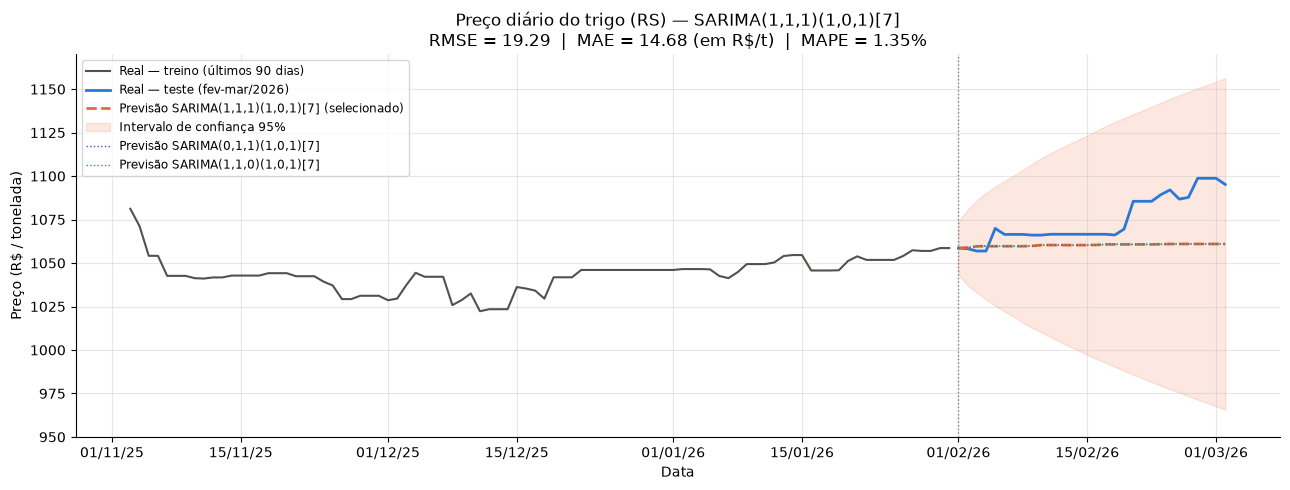

In [14]:
contexto = y_treino.iloc[-90:]   # últimos 90 dias do treino
cores_alt = {(0, 1, 1): "#7a3cc8", (1, 1, 0): "#1a9e77", (1, 1, 1): "#c0392b"}

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(contexto, color="#52514e", lw=1.5, label="Real — treino (últimos 90 dias)")
ax.plot(y_teste,  color="#2a78d6", lw=2,   label="Real — teste (fev-mar/2026)")
ax.plot(y_prev,   color="#eb6834", lw=2, ls="--", label=f"Previsão {nome_modelo(ORDEM)} (selecionado)")
ax.fill_between(intervalo.index, intervalo.iloc[:, 0], intervalo.iloc[:, 1],
                color="#eb6834", alpha=0.15, label="Intervalo de confiança 95%")

for ordem in CANDIDATOS:
    if ordem != ORDEM:
        ax.plot(previsoes[ordem], color=cores_alt[ordem], lw=1, ls=":", label=f"Previsão {nome_modelo(ordem)}")

ax.axvline(y_teste.index[0], color="gray", ls=":", lw=1)   # linha do corte treino/teste

ax.set_title(f"Preço diário do trigo (RS) — {nome_modelo(ORDEM)}\n"
             f"RMSE = {rmse:.2f}  |  MAE = {mae:.2f} (em R$/t)  |  MAPE = {mape:.2f}%")
ax.set_xlabel("Data")
ax.set_ylabel("Preço (R$ / tonelada)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y"))
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(950, 1170)   # escala fixa: usar a mesma nos gráficos de SARIMAX e LSTM do trigo, para comparação visual justa
ax.legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/sarima_previsao_trigo.png", dpi=150)
plt.show()

### 5.2 Exportação das métricas

Salvamos as métricas dos três candidatos em CSV, identificadas pela commodity no nome do arquivo, para montar a tabela comparativa com
SARIMAX e LSTM do trigo.

In [15]:
metricas.to_csv(f"{PASTA_SAIDA}/metricas_sarima_trigo.csv", index=False)

for arquivo in ["sarima_previsao_trigo.png", "metricas_sarima_trigo.csv"]:
    caminho = os.path.join(PASTA_SAIDA, arquivo)
    print(f"{caminho:<40} salvo: {os.path.exists(caminho)}  ({os.path.getsize(caminho):,} bytes)")

pd.read_csv(f"{PASTA_SAIDA}/metricas_sarima_trigo.csv")

outputs\sarima_previsao_trigo.png        salvo: True  (117,613 bytes)
outputs\metricas_sarima_trigo.csv        salvo: True  (244 bytes)


,modelo,AIC,BIC,RMSE,MAE,MAPE
0,"SARIMA(1,1,1)(1,0,1)[7]",45830.4932,45864.4476,19.2886,14.6769,1.3516
1,"SARIMA(0,1,1)(1,0,1)[7]",45832.4846,45859.6482,19.2760,14.6716,1.3512
2,"SARIMA(1,1,0)(1,0,1)[7]",45832.1576,45859.3211,19.2730,14.6685,1.3509


## Conclusão

- **Ajuste:** os três candidatos convergiram e os termos sazonais semanais são altamente significativos nos três
  ($\Phi_1 \approx 0{,}62$ a $0{,}64$ e $\Theta_1 \approx -0{,}51$ a $-0{,}54$), confirmando o ciclo semanal identificado na EDA.
- **Parte não sazonal redundante:** no modelo completo, $\phi_1 \approx -0{,}85$ e $\theta_1 \approx +0{,}83$ são individualmente
  significativos, mas **quase se cancelam** (fator comum $(1 + 0{,}85B) \approx (1 + 0{,}83B)$), sinal clássico de
  sobreparametrização. Nos modelos simplificados, o único termo não sazonal fica em ≈ −0,03. Isso é coerente com a EDA,
  que mostrou autocorrelação praticamente nula no lag 1, e explica por que os três candidatos produzem previsões quase idênticas.
- **Diagnóstico dos resíduos:** o Ljung-Box **não** acusa autocorrelação no lag 1 (p-valor de 0,44 a 0,95), mas acusa autocorrelação
  residual quando se consideram as defasagens até 7, 14 e 28 (p-valor ≈ 0 nos três modelos). Ou seja, as autocorrelações fracas, mas
  numerosas, das primeiras semanas (vistas na EDA) não são capturadas integralmente por estruturas tão parcimoniosas.
- **Seleção:** o **SARIMA(1,1,1)(1,0,1)[7]** tem o **menor AIC** e foi selecionado, mantendo a mesma especificação do arroz e,
  portanto, a comparabilidade entre as commodities. Ainda assim, a diferença de AIC para os outros candidatos é de apenas ≈ 2 pontos,
  e o BIC, mais rigoroso com parâmetros extras, favorece o (1,1,0) — que, por ter um parâmetro a menos e o mesmo desempenho,
  é uma alternativa igualmente defensável pelo princípio da parcimônia.
- **Previsão:** no horizonte de 30 dias de teste (01/02 a 02/03/2026), os três modelos produzem previsões **praticamente idênticas**,
  com erro médio de **≈ R\$ 14,7 por tonelada (MAPE ≈ 1,35%)** e RMSE ≈ R\$ 19,3/t. A previsão é quase uma linha reta próxima do último
  preço observado: como a variação diária do trigo quase não tem memória, o melhor que um modelo univariado consegue é projetar a
  inércia do preço.
- **Limitações:** a autocorrelação residual e a heterocedasticidade (variância dos choques maior a partir de 2020) indicam que o
  intervalo de confiança deve ser lido com cautela. O modelo também não usa informação externa, como o câmbio, que a EDA apontou como
  determinante do preço do trigo.
- **Papel no trabalho:** o SARIMA diário fica estabelecido como **baseline** do trigo. Os próximos modelos (SARIMAX e LSTM) precisam
  superar estas métricas para justificar sua complexidade adicional.